Exercise 1 — Bit-flip noise

Tasks:
1. Construct its density matrix.
2. Implement the bit-flip channel.
3. Apply noise probabilities of 0, 0.1, 0.2, 0.5 and 1.
4. Display the resulting density matrices.
5. Calculate the measurement probabilities for each output.
6. Plot the probability of measuring 1 against the noise probability.

Expected observation: At \(p=0\), the state remains \(|0\rangle\). At \(p=1\), it becomes \(|1\rangle\).

In [3]:
import numpy as np

def density_matrix(state):
    return np.outer(state, state.conj())

def measurement_probabilities(state):
    return np.abs(state) ** 2

def density_measurement_probabilities(rho):
    return np.real(np.diag(rho))

I = np.eye(2, dtype=complex)

X = np.array([
    [0, 1],
    [1, 0]
], dtype=complex)


def bit_flip_channel(rho, p):
    return (
        (1 - p) * rho
        + p * X @ rho @ X
    )

zero = np.array([1, 0], dtype=complex)

rho_zero = density_matrix(zero)

for p in [0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    rho = bit_flip_channel(rho_zero, p)
    probs = density_measurement_probabilities(rho)
    print(f"p={p:.1f}\n density matrix:\n {rho}\n probabilities: {probs}")

p=0.0
 density matrix:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
 probabilities: [1. 0.]
p=0.1
 density matrix:
 [[0.9+0.j 0. +0.j]
 [0. +0.j 0.1+0.j]]
 probabilities: [0.9 0.1]
p=0.2
 density matrix:
 [[0.8+0.j 0. +0.j]
 [0. +0.j 0.2+0.j]]
 probabilities: [0.8 0.2]
p=0.3
 density matrix:
 [[0.7+0.j 0. +0.j]
 [0. +0.j 0.3+0.j]]
 probabilities: [0.7 0.3]
p=0.4
 density matrix:
 [[0.6+0.j 0. +0.j]
 [0. +0.j 0.4+0.j]]
 probabilities: [0.6 0.4]
p=0.5
 density matrix:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
 probabilities: [0.5 0.5]


Exercise 2 — Phase-flip noise

Tasks:
1. Construct its density matrix.
2. Implement the phase-flip channel.
3. Apply noise probabilities of 0, 0.1, 0.2, 0.3, 0.4 and 0.5.
4. Display the density matrices.
5. Calculate their purities.
6. Calculate their fidelity with the original \(|+\rangle\) state.
7. Plot purity and fidelity against noise probability.

Expected observation: As phase-flip probability increases towards 0.5, the coherence disappears.

P=0.0
 Density matrix:
 [[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.9999999999999996
 Noise probability: 0.0
 Fidelity: 1.000

P=0.1
 Density matrix:
 [[0.5+0.j 0.4+0.j]
 [0.4+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.8199999999999996
 Noise probability: 0.1
 Fidelity: 0.900

P=0.2
 Density matrix:
 [[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.6799999999999997
 Noise probability: 0.2
 Fidelity: 0.800

P=0.3
 Density matrix:
 [[0.5+0.j 0.2+0.j]
 [0.2+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.5799999999999997
 Noise probability: 0.3
 Fidelity: 0.700

P=0.4
 Density matrix:
 [[0.5+0.j 0.1+0.j]
 [0.1+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.5199999999999998
 Noise probability: 0.4
 Fidelity: 0.600

P=0.5
 Density matrix:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.4999999999999998
 Noise probability: 0.5
 Fidelity: 0.500



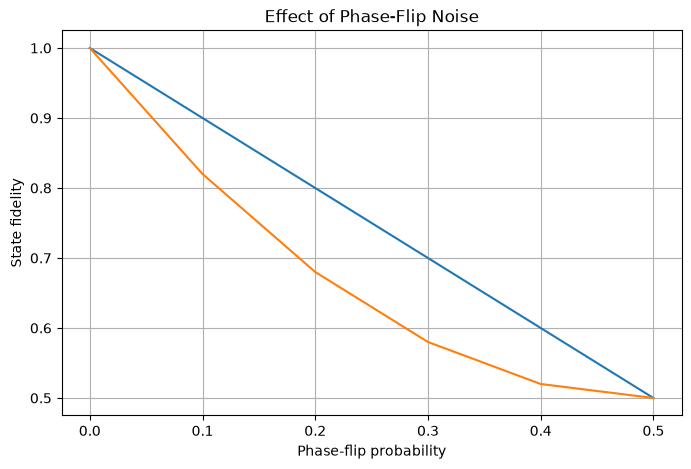

In [11]:
import matplotlib.pyplot as plt

plus = np.array([
    1 / np.sqrt(2),
    1 / np.sqrt(2)
], dtype=complex)

rho_plus = density_matrix(plus)

Z = np.array([
    [1, 0],
    [0, -1]
], dtype=complex)

def phase_flip_channel(rho, p):
    return (
        (1 - p) * rho
        + p * Z @ rho @ Z
    )

def purity(rho):
    return np.real(np.trace(rho @ rho))

def pure_state_fidelity(ideal_state, actual_rho):
    return np.real(
        np.vdot(
            ideal_state,
            actual_rho @ ideal_state
        )
    )


noise_levels = np.linspace(0, 0.5, 6)
fidelities = []
purities = []   

for p in [0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    rho = phase_flip_channel(rho_plus, p)
    probs = density_measurement_probabilities(rho)
    print(f"P={p:.1f}\n Density matrix:\n {rho}\n Probabilities: {probs}\n Purity: {purity(rho)}")
    
    F = pure_state_fidelity(plus, rho)
    fidelities.append(F)
    purities.append(purity(rho))

    print(f" Noise probability: {p:.1f}\n Fidelity: {F:.3f}\n")

plt.figure(figsize=(8, 5))

plt.plot(noise_levels, fidelities, label="Fidelity")
plt.plot(noise_levels, purities, label="Purity")

plt.xlabel("Phase-flip probability")
plt.ylabel("State fidelity")

plt.title("Effect of Phase-Flip Noise")

plt.grid(True)

plt.show()

Exercise 3 — Depolarizing noise

Tasks:
1. Implement the Pauli-Y matrix.
2. Implement the depolarizing channel using the convention taught today.
3. Apply noise probabilities of 0, 0.1, 0.2, 0.3, 0.4 and 0.5.
4. Display the resulting density matrices.
5. Calculate purity and fidelity.
6. Plot the results.

P=0.0
 Density matrix:
 [[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.9999999999999996
 Noise probability: 0.0
 Fidelity: 1.000

P=0.1
 Density matrix:
 [[0.5       +0.j 0.43333333+0.j]
 [0.43333333+0.j 0.5       +0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.8755555555555552
 Noise probability: 0.1
 Fidelity: 0.933

P=0.2
 Density matrix:
 [[0.5       +0.j 0.36666667+0.j]
 [0.36666667+0.j 0.5       +0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.7688888888888885
 Noise probability: 0.2
 Fidelity: 0.867

P=0.3
 Density matrix:
 [[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.6799999999999997
 Noise probability: 0.3
 Fidelity: 0.800

P=0.4
 Density matrix:
 [[0.5       +0.j 0.23333333+0.j]
 [0.23333333+0.j 0.5       +0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.6088888888888886
 Noise probability: 0.4
 Fidelity: 0.733

P=0.5
 Density matrix:
 [[0.5       +0.j 0.16666667+0.j]
 [0.16666667+0.j 0.5       +0.j]]
 Probabilities: [0.5 0.5]
 Pur

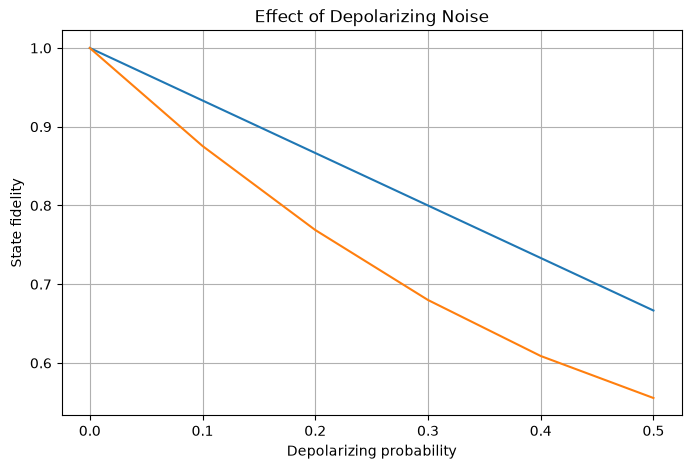

In [12]:
Y = np.array([
    [0, -1j],
    [1j, 0]
], dtype=complex)


def depolarizing_channel(rho, p):
    return (
        (1 - p) * rho
        + (p / 3) * X @ rho @ X
        + (p / 3) * Y @ rho @ Y
        + (p / 3) * Z @ rho @ Z
    )

fidelities = []
purities = [] 

for p in [0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    rho = depolarizing_channel(rho_plus, p)
    probs = density_measurement_probabilities(rho)
    print(f"P={p:.1f}\n Density matrix:\n {rho}\n Probabilities: {probs}\n Purity: {purity(rho)}")
    
    F = pure_state_fidelity(plus, rho)
    fidelities.append(F)
    purities.append(purity(rho))

    print(f" Noise probability: {p:.1f}\n Fidelity: {F:.3f}\n")

plt.figure(figsize=(8, 5))

plt.plot(noise_levels, fidelities, label="Fidelity")
plt.plot(noise_levels, purities, label="Purity")

plt.xlabel("Depolarizing probability")
plt.ylabel("State fidelity")

plt.title("Effect of Depolarizing Noise")

plt.grid(True)

plt.show()

Exercise 4 — Amplitude damping

Tasks:
1. Construct its density matrix.
2. Implement the two amplitude-damping Kraus operators.
3. Apply damping probabilities of 0, 0.1, 0.2, 0.5, 0.8 and 1.
4. Display the output density matrices.
5. Calculate the probabilities of measuring zero and one.
6. Plot the probability of measuring zero against damping probability.
7. Calculate the purity of each resulting state.

Expected observation: At \(\gamma=1\), the excited state has completely decayed into the ground state.

Gamma=0.0
 Density matrix:
 [[0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
 Probabilities: [0. 1.]
 Purity: 1.0
Gamma=0.1
 Density matrix:
 [[0.1+0.j 0. +0.j]
 [0. +0.j 0.9+0.j]]
 Probabilities: [0.1 0.9]
 Purity: 0.8199999999999998
Gamma=0.2
 Density matrix:
 [[0.2+0.j 0. +0.j]
 [0. +0.j 0.8+0.j]]
 Probabilities: [0.2 0.8]
 Purity: 0.6799999999999999
Gamma=0.5
 Density matrix:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
 Probabilities: [0.5 0.5]
 Purity: 0.5000000000000002
Gamma=0.8
 Density matrix:
 [[0.8+0.j 0. +0.j]
 [0. +0.j 0.2+0.j]]
 Probabilities: [0.8 0.2]
 Purity: 0.6799999999999998
Gamma=1.0
 Density matrix:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
 Probabilities: [1. 0.]
 Purity: 1.0


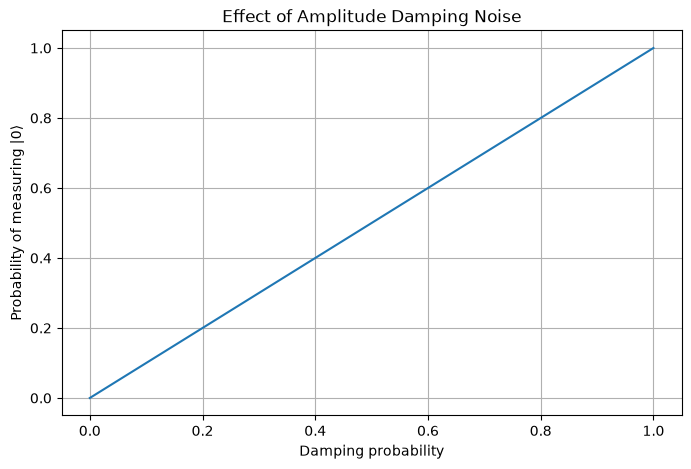

In [13]:
one = np.array([0, 1], dtype=complex)

rho_one = density_matrix(one)

def amplitude_damping_channel(rho, gamma):
    K0 = np.array([
        [1, 0],
        [0, np.sqrt(1 - gamma)]
    ], dtype=complex)

    K1 = np.array([
        [0, np.sqrt(gamma)],
        [0, 0]
    ], dtype=complex)

    return (
        K0 @ rho @ K0.conj().T
        + K1 @ rho @ K1.conj().T
    )

gamma_values = [0.0, 0.1, 0.2, 0.5, 0.8, 1.0]
probs_zero = []

for gamma in gamma_values:
    rho = amplitude_damping_channel(rho_one, gamma)
    probs = density_measurement_probabilities(rho)
    print(f"Gamma={gamma:.1f}\n Density matrix:\n {rho}\n Probabilities: {probs}\n Purity: {purity(rho)}")
    probs_zero.append(probs[0])
    
plt.figure(figsize=(8, 5))

plt.plot(gamma_values, probs_zero)

plt.xlabel("Damping probability")
plt.ylabel("Probability of measuring |0⟩")

plt.title("Effect of Amplitude Damping Noise")

plt.grid(True)

plt.show()     

Exercise 5 — Build a general Kraus simulator

Tasks:
1. Implement the general Kraus channel.
2. Implement Kraus operators for bit-flip noise.
3. Implement Kraus operators for phase-flip noise.
4. Implement Kraus operators for depolarizing noise.
5. Implement Kraus operators for amplitude damping.
6. Test all four channels using the same initial state.
7. Confirm that the general simulator produces the same results as your individual channel functions.

In [15]:
def apply_quantum_channel(rho, kraus_operators):

    result = np.zeros_like(rho, dtype=complex)

    for K in kraus_operators:
        result += K @ rho @ K.conj().T

    return result


def bit_flip_kraus(p):

    return [
        np.sqrt(1 - p) * I,
        np.sqrt(p) * X
    ]


def phase_flip_kraus(p):

    return [
        np.sqrt(1 - p) * I,
        np.sqrt(p) * Z
    ]


def depolarizing_kraus(p):

    return [
        np.sqrt(1 - p) * I,
        np.sqrt(p / 3) * X,
        np.sqrt(p / 3) * Y,
        np.sqrt(p / 3) * Z
    ]


def amplitude_damping_kraus(gamma):

    K0 = np.array([
        [1, 0],
        [0, np.sqrt(1 - gamma)]
    ], dtype=complex)

    K1 = np.array([
        [0, np.sqrt(gamma)],
        [0, 0]
    ], dtype=complex)

    return [K0, K1]


plus = np.array([
    1 / np.sqrt(2),
    1 / np.sqrt(2)
], dtype=complex)

rho_plus = np.outer(plus, plus.conj())

noisy_state = apply_quantum_channel(
    rho_plus,
    phase_flip_kraus(0.2)
)

print(noisy_state)


p = 0.2

tests = {
    "Bit flip": (
        bit_flip_channel(rho_plus, p),
        apply_quantum_channel(rho_plus, bit_flip_kraus(p))
    ),
    "Phase flip": (
        phase_flip_channel(rho_plus, p),
        apply_quantum_channel(rho_plus, phase_flip_kraus(p))
    ),
    "Depolarizing": (
        depolarizing_channel(rho_plus, p),
        apply_quantum_channel(rho_plus, depolarizing_kraus(p))
    ),
    "Amplitude damping": (
        amplitude_damping_channel(rho_plus, p),
        apply_quantum_channel(rho_plus, amplitude_damping_kraus(p))
    )
}

for name, (individual, general) in tests.items():
    print(name, np.allclose(individual, general))

[[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]
Bit flip True
Phase flip True
Depolarizing True
Amplitude damping True


Exercise 6 — Quantum channel validation

Tasks:
1. Check the Kraus completeness condition.
2. Check density-matrix Hermiticity.
3. Check that the trace equals one.
4. Check that all eigenvalues are nonnegative within numerical tolerance.
5. Validate the outputs of all four noise channels.
6. Test at least three different noise probabilities for each channel.

In [10]:
def validate_kraus_operators(kraus_operators):

    completeness = np.zeros((2, 2), dtype=complex)

    for K in kraus_operators:
        completeness += K.conj().T @ K

    return np.allclose(completeness, np.eye(2))


def validate_density_matrix(rho):

    hermitian = np.allclose(rho, rho.conj().T)

    trace_one = np.isclose(np.trace(rho), 1)

    eigenvalues = np.linalg.eigvalsh(rho)

    positive = np.all(eigenvalues >= -1e-10)

    return {
        "Hermitian": hermitian,
        "Trace equals one": trace_one,
        "Positive semidefinite": positive
    }


channels = {
    "Bit flip": bit_flip_kraus(0.2),
    "Phase flip": phase_flip_kraus(0.2),
    "Depolarizing": depolarizing_kraus(0.2),
    "Amplitude damping": amplitude_damping_kraus(0.2)
}

for name, operators in channels.items():

    print(
        name,
        validate_kraus_operators(operators)
    )

    

Bit flip True
Phase flip True
Depolarizing True
Amplitude damping True
